# **Movimiento Browniano**
Elaborado por: Jorge Luis Magaña Pichardo

In [1]:
import numpy as np
import random as r
import matplotlib.pyplot as plt

In [2]:
def brownie(T,L):
    veo = []
    w_0 = 0
    dt = T/L
    for _ in range(1,L):
        dw = r.gauss(0,1)
        w_1 = w_0 + np.sqrt(dt)*dw
        veo.append(w_1)
        
        w_0 = w_1
    veo.insert(0,0)
    return veo

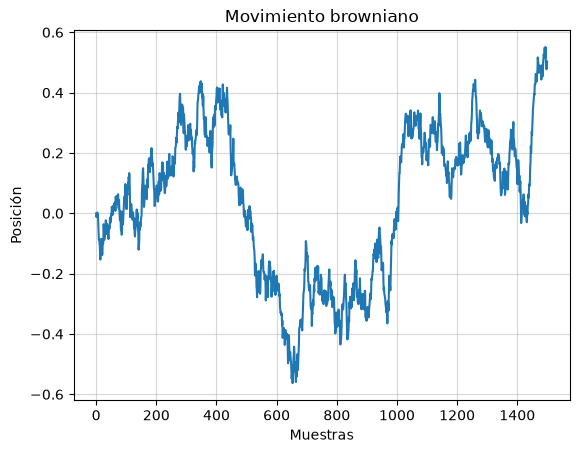

In [3]:
M = brownie(1,1500)
plt.title("Movimiento browniano")
plt.xlabel("Muestras")
plt.ylabel("Posición")
plt.grid(True, alpha=0.5)
plt.plot(M)
plt.show()




In [4]:
def reps(n,N): #n numero de repeticiones, N numero de muestras
    for i in range(n):
        M = brownie(1,N)
        plt.plot(M)
    plt.title("Repeticiones de Movimiento Browniano")
    plt.xlabel("Número de muestras")
    plt.ylabel("Posición")
    plt.grid(True, alpha=0.5)
    return

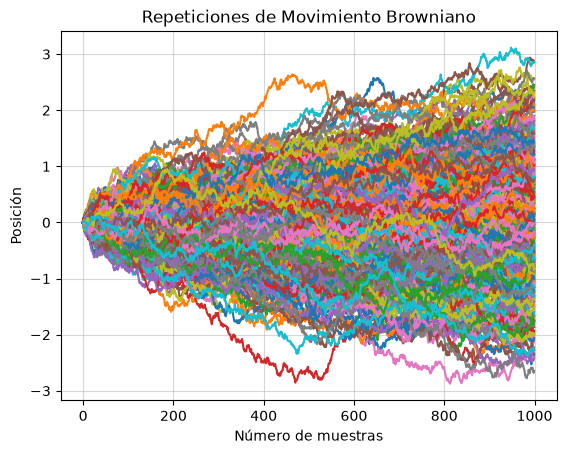

In [5]:
reps(500,1000)

In [6]:
def refi(T,lista):
    n = len(lista)
    T = 1
    dt = np.sqrt(T/n)
    pos = list(range(n-1))
    n_w = []
    refinada = []
    for i in range(1,n):
        dw = r.gauss(0,1)
        w_i = 1/2*(lista[i]+lista[i-1]) + np.sqrt(dt)*dw
        n_w.append(w_i)
        
    for i in range(len(n_w)):
        refinada.append(lista[i])
        refinada.append(n_w[i])
    refinada.append(lista[-1])    


    return refinada

In [7]:
def grafica_refinada(N):    
    S = brownie(1,N)
    A = refi(1,S)
    N =np.linspace(0,1,len(A))
    D =np.linspace(0,1,len(S))
    plt.title("Te quiero")
    plt.plot(N,A, color='gray', label ="Refinada", marker='o',markersize=3, markeredgecolor='black')
    plt.plot(D,S, color = 'red', label= 'original', marker='*', markersize=2)
    plt.grid(True, linestyle='-', alpha=0.5)
    plt.legend()
    plt.show()

    return 

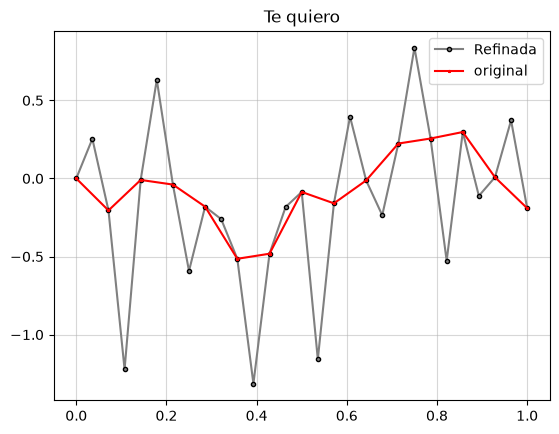

In [8]:
grafica_refinada(15)

# **PUENTE BROWNIANO**

Aqui la n son las particiones en las que se partira el brown

$$
B_t = B_t - t \cdot B_1
$$

In [75]:
def puente(T,n):
    mi_brown = brownie(T,n) #Para hacer un nuevo browniano
    mi_brown.insert(0,0) #Se inserta el punto 0 al inicio
    t = np.linspace(0, T, n+1) #El eje X
    lista_nueva = []
    for i in range(len(mi_brown)):
        lista_nueva.append(mi_brown[i] - t[i]*mi_brown[-1]) #Agrego valores de las restas de cada w(t)
    plt.title("Puentes")
    plt.plot(t, lista_nueva)
    plt.xlabel('Tiempo')
    plt.ylabel('Posición')
    plt.axhline(0, color='black', lw=0.5, linestyle='--')
    plt.grid(True, alpha = 0.5)
    return 



Hago un for para hacer mas brownianos

In [76]:
def puentes(n,N,T): #n: repeticiones N:Muestras para el movimiento browniano
    for i in range(n):
        puente(T,N)

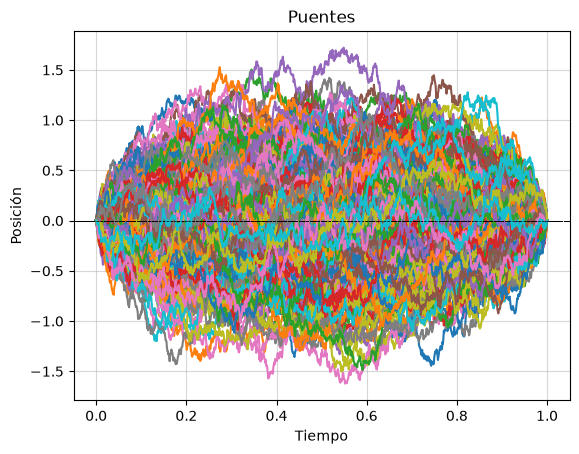

In [78]:
puentes(500,1000,1)

# Deriva

In [ ]:
def deriva(mu, sigma, T, n):
  A = np.array(brownie(T, n))
  t = np.linspace(0, T, n)

  veo = mu * t + sigma * A

  return veo.tolist() 

In [ ]:
def prob(mu, sigma, T, n, N):
  conteo = 0

  for _ in range(N):
    veo = deriva(mu, sigma, T, n)
    valor_final = veo[-1]  # X_t en el tiempo T = 4
    if 1 <= valor_final <= 3:
      conteo += 1

  # Calculamos la probabilidad
  probabilidad = conteo / N
  return probabilidad

In [79]:
prob(0.6,0.5,4,1000,1000)


0.644